# Model Building and Training

## Objective

The objective of this phase is to develop and compare
multiple supervised machine learning classification models
to predict whether a customer will subscribe to a term deposit.

The models will be evaluated using appropriate classification
metrics, with particular attention to the minority subscription
class.

## Models

- Dummy Classifier
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Loading and Preparing the Dataset

The original dataset is loaded and the same cleaning,
feature engineering and train-test splitting decisions
established in "03_preprocessing.ipynb" notebook are reproduced.

Preprocessing will subsequently be integrated into
the machine learning pipelines to prevent data leakage.

In [2]:
project_root = Path.cwd()

if not (project_root / "data" / "raw").exists():
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "bank-additional-full.csv"

df = pd.read_csv(data_path, sep=";")

print("Original dataset shape:", df.shape)


Original dataset shape: (41188, 21)


In [3]:
df_work = df.drop_duplicates(keep="first").copy()

X = df_work.drop(columns=["y", "duration"])
y = df_work["y"]

X["pdays_contact_recorded"] = (X["pdays"] != 999).astype(int)

X["pdays"] = X["pdays"].replace(999, np.nan)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (41176, 20)
Target shape: (41176,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

X_train: (32940, 20)
X_test: (8236, 20)

Training target distribution:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

Testing target distribution:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


In [5]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 10
Categorical features: 10


C:\Users\Administrator\AppData\Local\Temp\ipykernel_14352\2250657748.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [7]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## 2. Baseline Model

A Dummy Classifier is established as a baseline.
It provides a reference performance against which
the actual machine learning models can be compared.

The most frequent class strategy is used.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

Baseline Accuracy: 0.8873239436619719

Classification Report:
              precision    recall  f1-score   support

          no       0.89      1.00      0.94      7308
         yes       0.00      0.00      0.00       928

    accuracy                           0.89      8236
   macro avg       0.44      0.50      0.47      8236
weighted avg       0.79      0.89      0.83      8236



## 3. Logistic Regression

Logistic Regression is trained as the first predictive model.

A complete Scikit-learn Pipeline combines the preprocessing
transformations with the classifier.

This ensures that preprocessing is fitted only on the
training data during model training and cross-validation.

In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

### 3.1 Stratified 5-Fold Cross-Validation

Five-fold stratified cross-validation is used to assess
model performance across multiple validation subsets.

This provides a more reliable estimate of performance
than relying on a single validation split.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": make_scorer(
        precision_score,
        pos_label="yes",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="yes",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="yes",
        zero_division=0
    ),
    "roc_auc": "roc_auc"
}

In [12]:
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

In [13]:
logistic_cv_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Mean Score": [
        logistic_cv_results["test_precision"].mean(),
        logistic_cv_results["test_recall"].mean(),
        logistic_cv_results["test_f1"].mean(),
        logistic_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_cv_results["test_precision"].std(),
        logistic_cv_results["test_recall"].std(),
        logistic_cv_results["test_f1"].std(),
        logistic_cv_results["test_roc_auc"].std()
    ]
})

display(logistic_cv_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,Precision,0.6650,0.0216
1,Recall,0.2301,0.0040
2,F1-Score,0.3418,0.0039
3,ROC-AUC,0.7898,0.0071


In [17]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### Logistic Regression — Initial Findings

Logistic Regression was trained using a complete preprocessing
and classification pipeline.

Stratified 5-fold cross-validation was used to evaluate
precision, recall, F1-score and ROC-AUC.

These results will serve as a reference when comparing
more complex classification algorithms.

## 4. Decision Tree Classifier

A Decision Tree is a supervised learning algorithm that makes
predictions using a sequence of feature-based decisions.

Unlike Logistic Regression, it can capture non-linear relationships
and interactions between features.

The model will be evaluated using stratified 5-fold
cross-validation with the same metrics used for Logistic Regression.

In [19]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

In [20]:
decision_tree_cv_results = cross_validate(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

In [21]:
decision_tree_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Mean Score": [
        decision_tree_cv_results["test_precision"].mean(),
        decision_tree_cv_results["test_recall"].mean(),
        decision_tree_cv_results["test_f1"].mean(),
        decision_tree_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        decision_tree_cv_results["test_precision"].std(),
        decision_tree_cv_results["test_recall"].std(),
        decision_tree_cv_results["test_f1"].std(),
        decision_tree_cv_results["test_roc_auc"].std()
    ]
})

display(decision_tree_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,Precision,0.3103,0.0066
1,Recall,0.3385,0.0117
2,F1-Score,0.3237,0.0070
3,ROC-AUC,0.6239,0.0040


In [22]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


### Decision Tree — Initial Findings

The Decision Tree classifier was trained using the same
preprocessing pipeline and stratified 5-fold cross-validation
approach as Logistic Regression.

Its performance will be compared with Logistic Regression
to assess whether non-linear decision patterns improve
subscription prediction.

## 5. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines
multiple Decision Trees to make predictions.

Each tree is trained using a different sample of the training data
and considers subsets of features when making splits.

The final prediction is based on the combined predictions
of these trees.

Random Forest can reduce overfitting compared to a single
Decision Tree and often provides better generalization.

In [24]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [25]:
random_forest_cv_results = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

In [26]:
random_forest_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Mean Score": [
        random_forest_cv_results["test_precision"].mean(),
        random_forest_cv_results["test_recall"].mean(),
        random_forest_cv_results["test_f1"].mean(),
        random_forest_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        random_forest_cv_results["test_precision"].std(),
        random_forest_cv_results["test_recall"].std(),
        random_forest_cv_results["test_f1"].std(),
        random_forest_cv_results["test_roc_auc"].std()
    ]
})

display(random_forest_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,Precision,0.5471,0.0063
1,Recall,0.2897,0.0080
2,F1-Score,0.3787,0.0072
3,ROC-AUC,0.7741,0.0072


In [27]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### Random Forest — Initial Findings

The Random Forest classifier was trained using 100 decision trees
and the same preprocessing pipeline used for the previous models.

Stratified 5-fold cross-validation was used to evaluate
precision, recall, F1-score and ROC-AUC.

Its performance will be compared with Logistic Regression
and Decision Tree to assess the benefits of ensemble learning.

## 6. Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds
decision trees sequentially.

Each new tree attempts to correct errors made by the previous
trees, gradually improving the overall model.

Unlike Random Forest, which builds trees independently,
Gradient Boosting builds trees sequentially.

The model will be evaluated using stratified 5-fold
cross-validation with the same metrics as previous models.

In [28]:
categorical_transformer_dense = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_dense = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer_dense, categorical_features)
    ]
)

In [29]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor_dense),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [30]:
gradient_boosting_cv_results = cross_validate(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

In [31]:
gradient_boosting_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Mean Score": [
        gradient_boosting_cv_results["test_precision"].mean(),
        gradient_boosting_cv_results["test_recall"].mean(),
        gradient_boosting_cv_results["test_f1"].mean(),
        gradient_boosting_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        gradient_boosting_cv_results["test_precision"].std(),
        gradient_boosting_cv_results["test_recall"].std(),
        gradient_boosting_cv_results["test_f1"].std(),
        gradient_boosting_cv_results["test_roc_auc"].std()
    ]
})

display(gradient_boosting_summary.round(4))

,Metric,Mean Score,Standard Deviation
0,Precision,0.6662,0.0206
1,Recall,0.2517,0.0053
2,F1-Score,0.3653,0.0074
3,ROC-AUC,0.7956,0.0082


In [32]:
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


### Gradient Boosting — Initial Findings

The Gradient Boosting classifier was trained using
100 boosting stages and a maximum tree depth of 3.

The model was evaluated using stratified 5-fold
cross-validation with precision, recall, F1-score
and ROC-AUC.

Its performance will be compared with the other
classification algorithms during model selection.

## 7. Model Comparison

The performance of the four classification algorithms is compared
using stratified 5-fold cross-validation.

Precision, recall, F1-score and ROC-AUC are used as evaluation
metrics, with particular attention to identifying the minority
class (customers who subscribe to a term deposit).

The comparison will help identify a suitable candidate
for further evaluation and improvement.

In [34]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_cv_results = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

In [35]:
model_results = {
    "Dummy Classifier": dummy_cv_results,
    "Logistic Regression": logistic_cv_results,
    "Decision Tree": decision_tree_cv_results,
    "Random Forest": random_forest_cv_results,
    "Gradient Boosting": gradient_boosting_cv_results
}

comparison_data = []

for model_name, results in model_results.items():
    comparison_data.append({
        "Model": model_name,
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1-Score": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    })

model_comparison = pd.DataFrame(comparison_data)

model_comparison = model_comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.5471,0.2897,0.3787,0.7741
1,Gradient Boosting,0.6662,0.2517,0.3653,0.7956
2,Logistic Regression,0.6650,0.2301,0.3418,0.7898
3,Decision Tree,0.3103,0.3385,0.3237,0.6239
4,Dummy Classifier,0.0000,0.0000,0.0000,0.5000


### Initial Model Comparison — Observations

The five models were evaluated using stratified 5-fold
cross-validation on the training dataset.

The comparison considers precision, recall, F1-score
and ROC-AUC.

The results will guide the selection of a candidate model
for further evaluation, including improvements in
minority-class prediction.

## 8. Handling Class Imbalance

The target variable is imbalanced, with approximately 88.7%
of records belonging to the "no" class and 11.3% to the "yes" class.

To improve the detection of potential subscribers, class weighting
is explored for Logistic Regression, Decision Tree and Random Forest.

The balanced class-weight option assigns greater importance
to the minority class during model training.

The models will be evaluated using the same stratified
5-fold cross-validation approach.

In [36]:
logistic_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

decision_tree_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

In [37]:
balanced_models = {
    "Logistic Regression (Balanced)": logistic_balanced,
    "Decision Tree (Balanced)": decision_tree_balanced,
    "Random Forest (Balanced)": random_forest_balanced
}

balanced_results = {}

for model_name, model in balanced_models.items():
    balanced_results[model_name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    print(f"{model_name} completed.")

Logistic Regression (Balanced) completed.
Decision Tree (Balanced) completed.
Random Forest (Balanced) completed.


In [38]:
balanced_comparison_data = []

for model_name, results in balanced_results.items():
    balanced_comparison_data.append({
        "Model": model_name,
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1-Score": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    })

balanced_comparison = pd.DataFrame(balanced_comparison_data)

display(
    balanced_comparison.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Balanced),0.3525,0.6230,0.4502,0.7906
1,Random Forest (Balanced),0.4359,0.4589,0.4470,0.7759
2,Decision Tree (Balanced),0.3196,0.3301,0.3247,0.6209


In [39]:
original_results = {
    "Logistic Regression": logistic_cv_results,
    "Decision Tree": decision_tree_cv_results,
    "Random Forest": random_forest_cv_results
}

comparison_rows = []

for model_name, results in original_results.items():
    balanced_name = f"{model_name} (Balanced)"
    balanced_result = balanced_results[balanced_name]

    for metric in ["precision", "recall", "f1"]:
        original_score = results[f"test_{metric}"].mean()
        balanced_score = balanced_result[f"test_{metric}"].mean()

        comparison_rows.append({
            "Model": model_name,
            "Metric": metric.upper(),
            "Original": original_score,
            "Balanced": balanced_score,
            "Change": balanced_score - original_score
        })

weight_comparison = pd.DataFrame(comparison_rows)

display(weight_comparison.round(4))

,Model,Metric,Original,Balanced,Change
0,Logistic Regression,PRECISION,0.6650,0.3525,-0.3125
1,Logistic Regression,RECALL,0.2301,0.6230,0.3929
2,Logistic Regression,F1,0.3418,0.4502,0.1084
3,Decision Tree,PRECISION,0.3103,0.3196,0.0093
4,Decision Tree,RECALL,0.3385,0.3301,-0.0084
5,Decision Tree,F1,0.3237,0.3247,0.0010
6,Random Forest,PRECISION,0.5471,0.4359,-0.1112
7,Random Forest,RECALL,0.2897,0.4589,0.1692
8,Random Forest,F1,0.3787,0.4470,0.0682


### Class Weighting — Findings

Class weighting was evaluated for Logistic Regression,
Decision Tree and Random Forest.

The original and balanced versions were compared using
precision, recall and F1-score.

The results will help determine whether class weighting
improves the detection of potential subscribers.

## 9. Decision Threshold Tuning

The default classification threshold of 0.5 may not provide
the desired balance between precision and recall.

Threshold tuning is performed for the balanced Logistic Regression
and Random Forest models.

Out-of-fold predicted probabilities from stratified 5-fold
cross-validation are used to evaluate different thresholds.

The objective is to improve subscriber detection while
maintaining a reasonable precision level.

In [40]:
from sklearn.model_selection import cross_val_predict

lr_oof_probabilities = cross_val_predict(
    logistic_balanced,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

rf_oof_probabilities = cross_val_predict(
    random_forest_balanced,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

positive_class_index = list(np.unique(y_train)).index("yes")

lr_oof_probabilities = lr_oof_probabilities[:, positive_class_index]
rf_oof_probabilities = rf_oof_probabilities[:, positive_class_index]

print("Out-of-fold probabilities generated.")

Out-of-fold probabilities generated.


In [41]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

def evaluate_thresholds(y_true, probabilities, model_name):
    results = []

    for threshold in thresholds:
        predictions = np.where(probabilities >= threshold, "yes", "no")

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions, pos_label="yes", zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, pos_label="yes", zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, predictions, pos_label="yes", zero_division=0
            )
        })

    return pd.DataFrame(results)

In [42]:
lr_threshold_results = evaluate_thresholds(
    y_train,
    lr_oof_probabilities,
    "Logistic Regression (Balanced)"
)

rf_threshold_results = evaluate_thresholds(
    y_train,
    rf_oof_probabilities,
    "Random Forest (Balanced)"
)

threshold_comparison = pd.concat(
    [lr_threshold_results, rf_threshold_results],
    ignore_index=True
)

display(threshold_comparison.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression (Balanced),0.20,0.1220,0.9736,0.2169
1,Logistic Regression (Balanced),0.25,0.1403,0.9224,0.2436
2,Logistic Regression (Balanced),0.30,0.1635,0.8566,0.2746
3,Logistic Regression (Balanced),0.35,0.2077,0.7736,0.3274
4,Logistic Regression (Balanced),0.40,0.2597,0.7022,0.3792
5,Logistic Regression (Balanced),0.45,0.3065,0.6548,0.4176
6,Logistic Regression (Balanced),0.50,0.3524,0.6230,0.4502
7,Logistic Regression (Balanced),0.55,0.3792,0.6047,0.4661
8,Logistic Regression (Balanced),0.60,0.3973,0.5918,0.4754
9,Random Forest (Balanced),0.20,0.2618,0.6906,0.3796


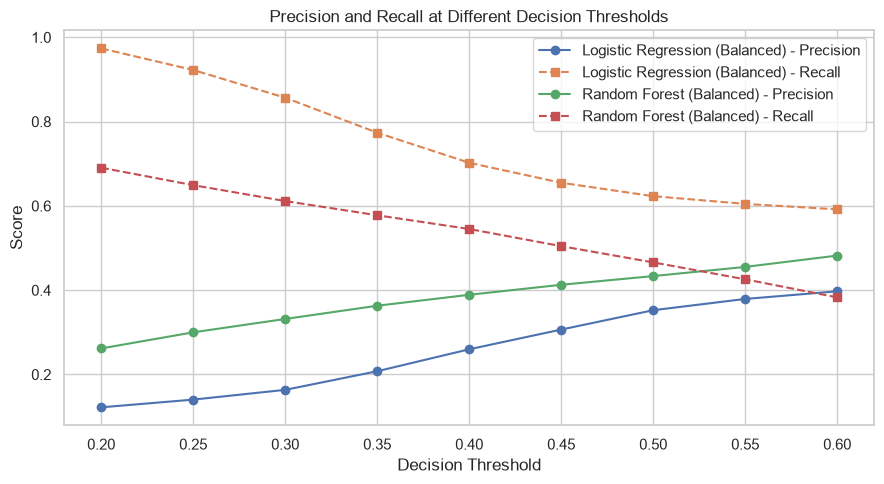

In [43]:
plt.figure(figsize=(9, 5))

for model_name in threshold_comparison["Model"].unique():
    model_data = threshold_comparison[
        threshold_comparison["Model"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label=f"{model_name} - Precision"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="s",
        linestyle="--",
        label=f"{model_name} - Recall"
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Decision Thresholds")
plt.legend()
plt.tight_layout()
plt.show()

### Decision Threshold Tuning — Findings

Out-of-fold predicted probabilities were generated using
stratified 5-fold cross-validation.

Different classification thresholds were evaluated for
balanced Logistic Regression and Random Forest.

Precision, recall and F1-score were compared to understand
the effect of threshold selection on subscriber detection.

The final threshold will be selected based on the observed
precision-recall trade-off.

## 10. Final Model Evaluation

Based on cross-validation and threshold comparison,
balanced Logistic Regression was selected as the final
candidate model.

A decision threshold of 0.55 was selected to maintain
recall above 60% while improving the F1-score.

The selected pipeline is fitted on the complete training
dataset and evaluated on the held-out test dataset.

In [44]:
final_model = logistic_balanced

final_model.fit(X_train, y_train)

print("Final model training completed.")

Final model training completed.


In [45]:
final_threshold = 0.55

test_probabilities = final_model.predict_proba(X_test)

positive_class_index = list(final_model.classes_).index("yes")

test_yes_probabilities = test_probabilities[:, positive_class_index]

test_predictions = np.where(
    test_yes_probabilities >= final_threshold,
    "yes",
    "no"
)

print("Test predictions generated.")

Test predictions generated.


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC (Average Precision)"
    ],
    "Test Score": [
        accuracy_score(y_test, test_predictions),
        precision_score(y_test, test_predictions, pos_label="yes"),
        recall_score(y_test, test_predictions, pos_label="yes"),
        f1_score(y_test, test_predictions, pos_label="yes"),
        roc_auc_score(
            (y_test == "yes").astype(int),
            test_yes_probabilities
        ),
        average_precision_score(
            (y_test == "yes").astype(int),
            test_yes_probabilities
        )
    ]
})

display(final_metrics.round(4))

,Metric,Test Score
0,Accuracy,0.8465
1,Precision,0.3887
2,Recall,0.6325
3,F1-Score,0.4815
4,ROC-AUC,0.8001
5,PR-AUC (Average Precision),0.4459


In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=["no", "yes"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
)

display(cm_df)

,Predicted No,Predicted Yes
Actual No,6385,923
Actual Yes,341,587


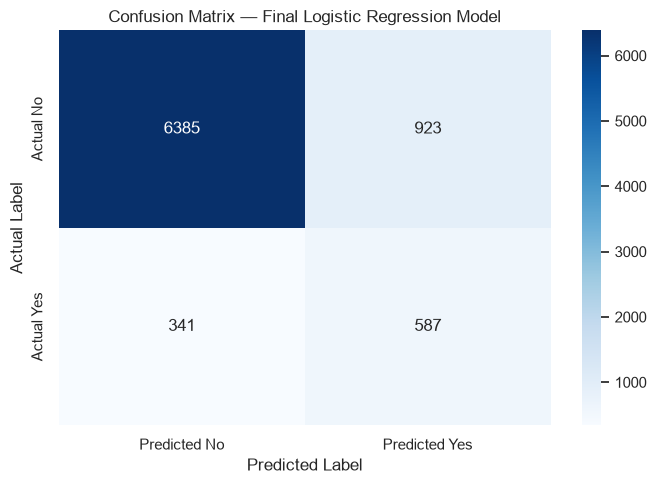

In [48]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix — Final Logistic Regression Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        test_predictions,
        labels=["no", "yes"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

          no       0.95      0.87      0.91      7308
         yes       0.39      0.63      0.48       928

    accuracy                           0.85      8236
   macro avg       0.67      0.75      0.70      8236
weighted avg       0.89      0.85      0.86      8236



### Final Model — Evaluation Findings

Balanced Logistic Regression was selected based on its
cross-validation performance and threshold analysis.

The model was trained on the complete training dataset
and evaluated on the held-out test dataset using a
decision threshold of 0.55.

Final performance was assessed using accuracy, precision,
recall, F1-score, ROC-AUC, PR-AUC and the confusion matrix.

The results provide an estimate of the model's ability
to identify potential term deposit subscribers on unseen data.

In [50]:
import joblib

model_path = project_root / "models" / "bank_term_deposit_pipeline.joblib"

joblib.dump(
    {
        "model": final_model,
        "threshold": final_threshold,
        "positive_class": "yes"
    },
    model_path
)

print(f"Model saved at: {model_path}")

Model saved at: c:\Users\Administrator\OneDrive\Documents\bank-term-deposit-prediction\models\bank_term_deposit_pipeline.joblib
